In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files

In [2]:
os.makedirs('images', exist_ok=True)

print("Please Upload The Required Images:")
print("- box.png")
print("- box_in_scene.png")
print("- 10tomani.jpg")
print("- 50tomani.jpg")
print("- 100tomani.jpg")
print("- eskenas.jpg")

uploaded = files.upload()

for filename in uploaded.keys():
  dest = os.path.join('images', filename)
  os.rename(filename, dest)
  print(f'Uploaded: {filename}')

print("\nContents Of Images Folder:")
print(os.listdir('images'))

Please Upload The Required Images:
- box.png
- box_in_scene.png
- 10tomani.jpg
- 50tomani.jpg
- 100tomani.jpg
- eskenas.jpg


Saving 10tomani.jpg to 10tomani.jpg
Saving 50tomani.jpg to 50tomani.jpg
Saving 100tomani.jpg to 100tomani.jpg
Saving box.png to box.png
Saving box_in_scene.png to box_in_scene.png
Saving eskenas.jpg to eskenas.jpg
Uploaded: 10tomani.jpg
Uploaded: 50tomani.jpg
Uploaded: 100tomani.jpg
Uploaded: box.png
Uploaded: box_in_scene.png
Uploaded: eskenas.jpg

Contents Of Images Folder:
['100tomani.jpg', '10tomani.jpg', 'box_in_scene.png', 'eskenas.jpg', '50tomani.jpg', 'box.png']


In [3]:
img1 =cv2.imread('images/box.png', 0)
img2 =cv2.imread('images/box_in_scene.png', 0)

sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

FLANN_INDEX_KDTREE = 1
index_params = dict(algorithm=FLANN_INDEX_KDTREE, trees=5)
search_params = dict(checks=50)

flann = cv2.FlannBasedMatcher(index_params, search_params)
matches = flann.knnMatch(des1, des2, k=2)

good_matches = []
for m, n in matches:
    if m.distance < 0.7 * n.distance:
        good_matches.append(m)

In [5]:
MIN_MATCH_COUNT = 10

if len(good_matches) > MIN_MATCH_COUNT:
  scr_pts = np.float32([ kp1[m.queryIdx].pt for m in good_matches ]).reshape(-1, 1, 2)
  dst_pts = np.float32([ kp2[m.trainIdx].pt for m in good_matches ]).reshape(-1, 1, 2)
  M, mask = cv2.findHomography(scr_pts, dst_pts, cv2.RANSAC, 5.0)
  matchesMask = mask.ravel().tolist()
  h, w = img1.shape
  pts = np.float32([ [0, 0], [0, h-1], [w-1, h-1], [w-1, 0] ]).reshape(-1, 1, 2)
  dst = cv2.perspectiveTransform(pts, M)
  im2 = cv2.polylines(img2, [np.int32(dst)], True, 255, 3, cv2.LINE_AA)

else:
  print( "Not Enough Matches Are Found - {}/{}".format(len(good_matches), MIN_MATCH_COUNT))
  matchesMask = None

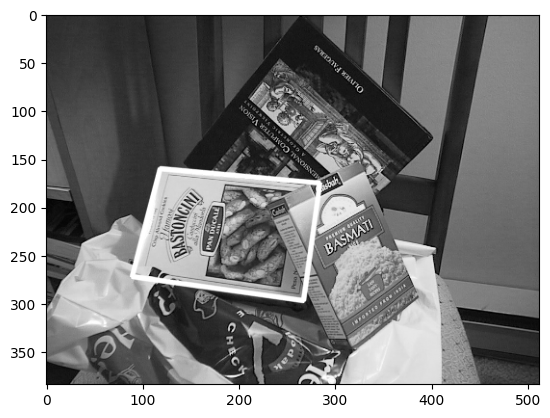

In [6]:
plt.imshow(im2, 'gray')

plt.show()

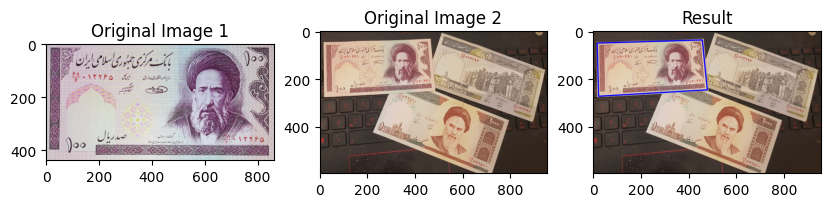

In [10]:
original_img1 = cv2.imread('images/10tomani.jpg')
original_img2 = cv2.imread('images/eskenas.jpg')

result = original_img2.copy()
img1 = cv2.cvtColor(original_img1, cv2.COLOR_BGR2GRAY)
img2 = cv2.cvtColor(original_img2, cv2.COLOR_BGR2GRAY)

sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

FLANN_INDEX_KDTREE = 1
index_params = dict(algorithm=FLANN_INDEX_KDTREE, trees=5)
search_params = dict(checks=50)

flann = cv2.FlannBasedMatcher(index_params, search_params)
matches = flann.knnMatch(des1, des2, k=2)

good_matches = []
for m, n in matches:
    if m.distance < 0.7 * n.distance:
        good_matches.append(m)

MIN_MATCH_COUNT = 10

if len(good_matches) > MIN_MATCH_COUNT:
  scr_pts = np.float32([ kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
  dst_pts = np.float32([ kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
  M, mask = cv2.findHomography(scr_pts, dst_pts, cv2.RANSAC, 0.5)
  matchesMask = mask.ravel().tolist()
  h, w = img1.shape
  pts = np.float32([ [0,0],[0,h-1],[w-1,h-1],[w-1,0] ]).reshape(-1, 1, 2)
  dst = cv2.perspectiveTransform(pts, M)
  result = cv2.polylines(result, [np.int32(dst)], True, 255, 3, cv2.LINE_AA)
else:
  print( "Not Enough Matches Are Found - {}/{}".format(len(good_matches), MIN_MATCH_COUNT))
  matchesMask = None

plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_img1[..., ::-1])
plt.title('Original Image 1')

plt.subplot(1, 3, 2)
plt.imshow(original_img2[..., ::-1])
plt.title('Original Image 2')

plt.subplot(1, 3, 3)
plt.imshow(result[..., ::-1])
plt.title('Result')

plt.show()

In [9]:
dst

array([[[ 14.099267,  48.32416 ]],

       [[ 19.336748, 274.3879  ]],

       [[478.9997  , 246.78024 ]],

       [[457.4307  ,  38.752426]]], dtype=float32)

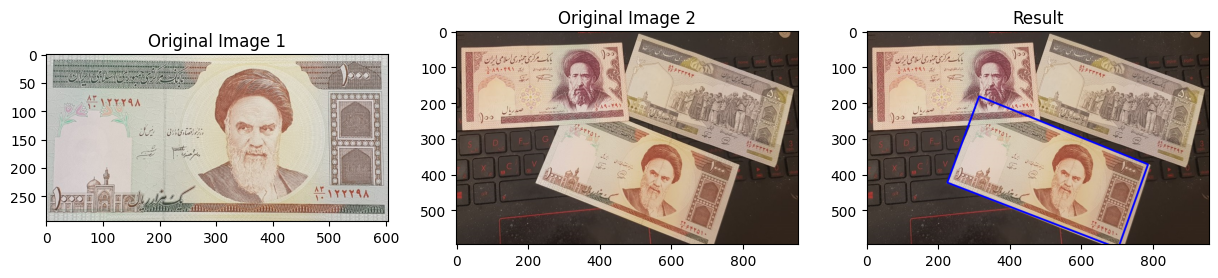

In [11]:
original_img1 = cv2.imread('images/100tomani.jpg')
original_img2 = cv2.imread('images/eskenas.jpg')

result = original_img2.copy()
img1 = cv2.cvtColor(original_img1, cv2.COLOR_BGR2GRAY)
img2 = cv2.cvtColor(original_img2, cv2.COLOR_BGR2GRAY)

sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

FLANN_INDEX_KDTREE = 1
index_params = dict(algorithm=FLANN_INDEX_KDTREE, trees=5)
search_params = dict(checks=50)

flann = cv2.FlannBasedMatcher(index_params, search_params)
matches = flann.knnMatch(des1, des2, k=2)

good_matches = []
for m, n in matches:
    if m.distance < 0.7 * n.distance:
        good_matches.append(m)

MIN_MATCH_COUNT = 10

if len(good_matches) > MIN_MATCH_COUNT:
  scr_pts = np.float32([ kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
  dst_pts = np.float32([ kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
  M, mask = cv2.findHomography(scr_pts, dst_pts, cv2.RANSAC, 0.5)
  matchesMask = mask.ravel().tolist()
  h, w = img1.shape
  pts = np.float32([ [0,0],[0,h-1],[w-1,h-1],[w-1,0] ]).reshape(-1, 1, 2)
  dst = cv2.perspectiveTransform(pts, M)
  result = cv2.polylines(result, [np.int32(dst)], True, 255, 3, cv2.LINE_AA)
else:
  print( "Not Enough Matches Are Found - {}/{}".format(len(good_matches), MIN_MATCH_COUNT))
  matchesMask = None

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_img1[..., ::-1])
plt.title('Original Image 1')

plt.subplot(1, 3, 2)
plt.imshow(original_img2[..., ::-1])
plt.title('Original Image 2')

plt.subplot(1, 3, 3)
plt.imshow(result[..., ::-1])
plt.title('Result')

plt.show()

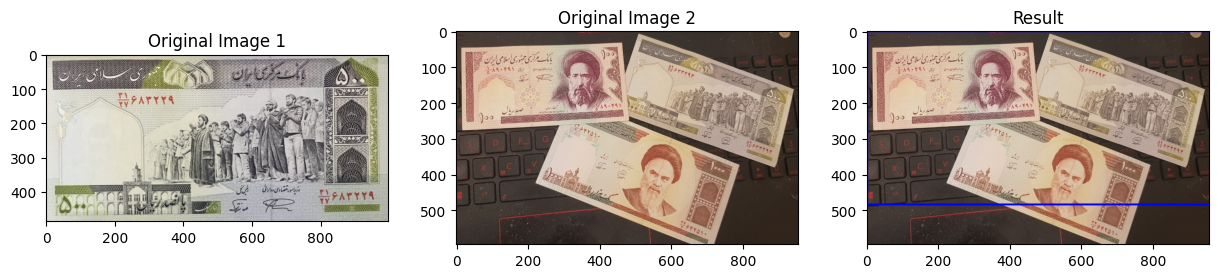

In [12]:
original_img1 = cv2.imread('images/50tomani.jpg')
original_img2 = cv2.imread('images/eskenas.jpg')

result = original_img2.copy()
img1 = cv2.cvtColor(original_img1, cv2.COLOR_BGR2GRAY)
img2 = cv2.cvtColor(original_img2, cv2.COLOR_BGR2GRAY)

sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img1, None)

FLANN_INDEX_KDTREE = 1
index_params = dict(algorithm = FLANN_INDEX_KDTREE, trees = 5)
search_params = dict(checks = 50)

flann = cv2.FlannBasedMatcher(index_params, search_params)
matches = flann.knnMatch(des1, des2, k=2)

good_matches = []
for m, n in matches:
  if m.distance < 0.7 * n.distance:
    good_matches.append(m)

MIN_MATCH_COUNT = 10

if len(good_matches) > MIN_MATCH_COUNT:
  scr_pts = np.float32([ kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
  dst_pts = np.float32([ kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
  M, mask = cv2.findHomography(scr_pts, dst_pts, cv2.RANSAC, 0.5)
  matchesMask = mask.ravel().tolist()
  h, w = img1.shape
  pts = np.float32([ [0,0],[0,h-1],[w-1,h-1],[w-1,0] ]).reshape(-1, 1, 2)
  dst = cv2.perspectiveTransform(pts, M)
  result = cv2.polylines(result, [np.int32(dst)], True, 255, 3, cv2.LINE_AA)
else:
  print( "Not Enough Matches Are Found - {}/{}".format(len(good_matches), MIN_MATCH_COUNT))
  matchesMask = None

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_img1[..., ::-1])
plt.title('Original Image 1')

plt.subplot(1, 3, 2)
plt.imshow(original_img2[..., ::-1])
plt.title('Original Image 2')

plt.subplot(1, 3, 3)
plt.imshow(result[..., ::-1])
plt.title('Result')

plt.show()